In [1]:
#importing libraries
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt

from src.data_loader import load_raw_data, load_id_mappings

pd.set_option("display.max_columns", 60)

In [2]:
#loading raw data and creating target with boolean mask
df = load_raw_data()
df["readmitted_30"] = (df["readmitted"] == "<30").astype(int)
print(df.shape)
df.head()

(101766, 51)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,readmitted_30
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO,0
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30,0
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO,0
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO,0
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO,0


In [3]:
#checking column types
df.dtypes.value_counts()

str      37
int64    14
Name: count, dtype: int64

In [4]:
#checking missing values in percent
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
(missing / len(df) * 100).round(1)

weight               96.9
medical_specialty    49.1
payer_code           39.6
race                  2.2
diag_3                1.4
diag_2                0.4
diag_1                0.0
dtype: float64

In [5]:
#checking lab results, None means not tested
print(df["max_glu_serum"].value_counts())
print(df["A1Cresult"].value_counts())

max_glu_serum
None    96420
Norm     2597
>200     1485
>300     1264
Name: count, dtype: int64
A1Cresult
None    84748
>8       8216
Norm     4990
>7       3812
Name: count, dtype: int64


In [6]:
#checking readmitted values
df["readmitted"].value_counts()

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

In [7]:
#checking target balance
print(df["readmitted_30"].value_counts())
print(df["readmitted_30"].value_counts(normalize=True).round(3))

readmitted_30
0    90409
1    11357
Name: count, dtype: int64
readmitted_30
0    0.888
1    0.112
Name: proportion, dtype: float64


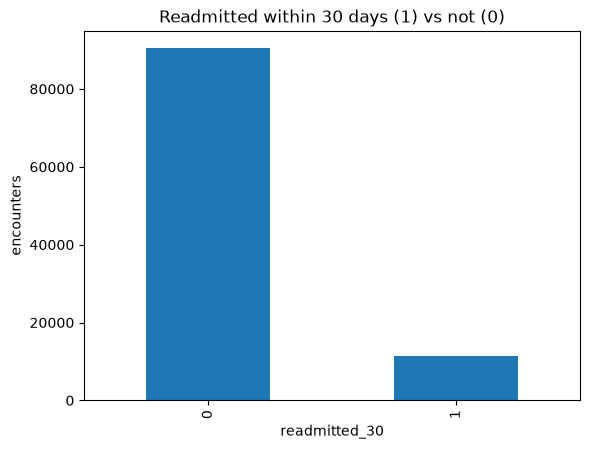

In [8]:
#plotting the class balance
df["readmitted_30"].value_counts().plot(kind="bar")
plt.title("Readmitted within 30 days (1) vs not (0)")
plt.ylabel("encounters")
plt.show()

In [9]:
#checking numeric columns
num_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
            "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
time_in_hospital,101766.0,4.40,2.99,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101766.0,43.10,19.67,1.0,31.0,44.0,57.0,132.0
num_procedures,101766.0,1.34,1.71,0.0,0.0,1.0,2.0,6.0
num_medications,101766.0,16.02,8.13,1.0,10.0,15.0,20.0,81.0
number_outpatient,101766.0,0.37,1.27,0.0,0.0,0.0,0.0,42.0
number_emergency,101766.0,0.20,0.93,0.0,0.0,0.0,0.0,76.0
number_inpatient,101766.0,0.64,1.26,0.0,0.0,0.0,1.0,21.0
number_diagnoses,101766.0,7.42,1.93,1.0,6.0,8.0,9.0,16.0


In [10]:
#checking skewness
df[num_cols].skew().sort_values(ascending=False).round(2)

number_emergency      22.86
number_outpatient      8.83
number_inpatient       3.61
num_medications        1.33
num_procedures         1.32
time_in_hospital       1.13
num_lab_procedures    -0.24
number_diagnoses      -0.88
dtype: float64

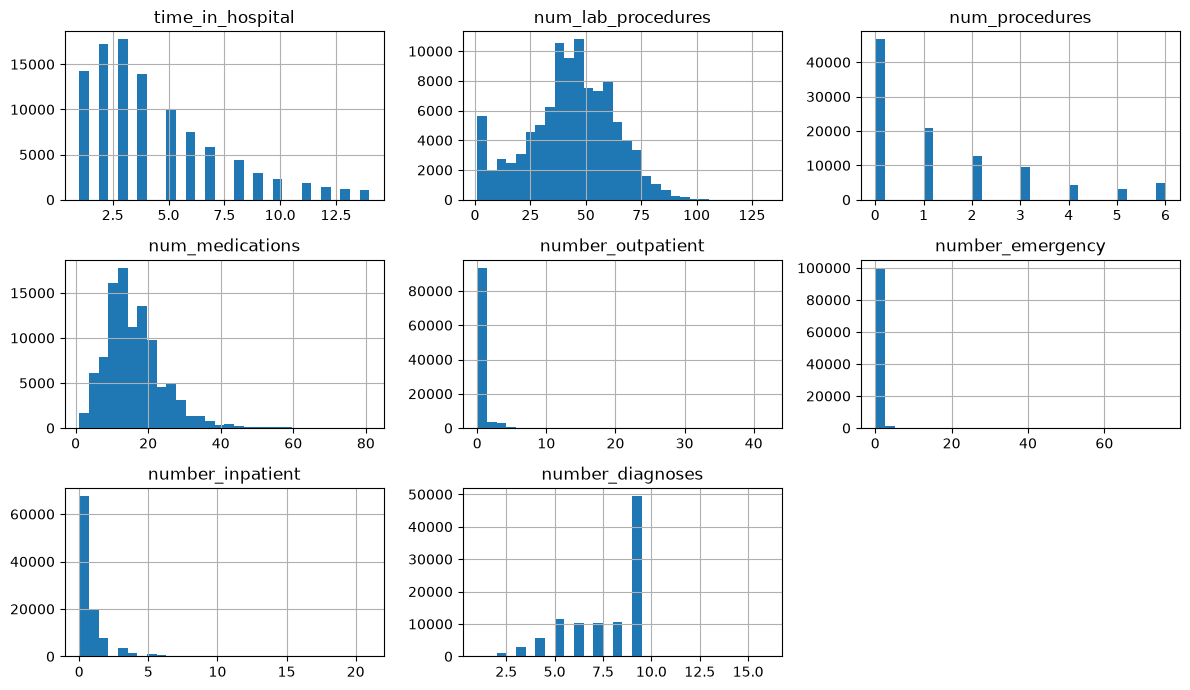

In [11]:
#plotting numeric columns
df[num_cols].hist(bins=30, figsize=(12, 7))
plt.tight_layout()
plt.show()

In [12]:
#checking unique values in text columns
text_cols = df.select_dtypes(exclude="number").columns
df[text_cols].nunique().sort_values(ascending=False)

diag_3                      789
diag_2                      748
diag_1                      716
medical_specialty            72
payer_code                   17
age                          10
weight                        9
race                          5
glipizide                     4
glyburide-metformin           4
insulin                       4
miglitol                      4
acarbose                      4
rosiglitazone                 4
pioglitazone                  4
glyburide                     4
chlorpropamide                4
nateglinide                   4
repaglinide                   4
metformin                     4
glimepiride                   4
A1Cresult                     4
max_glu_serum                 4
readmitted                    3
gender                        3
tolazamide                    3
glimepiride-pioglitazone      2
diabetesMed                   2
change                        2
metformin-pioglitazone        2
metformin-rosiglitazone       2
acetohex

In [13]:
#finding constant columns
unq_values = df.nunique()
unq_values[unq_values == 1]

examide        1
citoglipton    1
dtype: int64

In [14]:
#checking gender values
df["gender"].value_counts()

gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64

In [15]:
#checking age ranges
df["age"].value_counts().sort_index()

age
[0-10)        161
[10-20)       691
[20-30)      1657
[30-40)      3775
[40-50)      9685
[50-60)     17256
[60-70)     22483
[70-80)     26068
[80-90)     17197
[90-100)     2793
Name: count, dtype: int64

In [16]:
#checking diagnosis codes
print(df["diag_1"].nunique(), df["diag_2"].nunique(), df["diag_3"].nunique())
df["diag_1"].value_counts().head(10)

716 748 789


diag_1
428    6862
414    6581
786    4016
410    3614
486    3508
427    2766
491    2275
715    2151
682    2042
434    2028
Name: count, dtype: int64

In [17]:
#counting visits per medicine
med_cols = ["metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride", "acetohexamide",
            "glipizide", "glyburide", "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose", "miglitol",
            "troglitazone", "tolazamide", "examide", "citoglipton", "insulin", "glyburide-metformin",
            "glipizide-metformin", "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone"]
(df[med_cols] != "No").sum().sort_values(ascending=False)

insulin                     54383
metformin                   19988
glipizide                   12686
glyburide                   10650
pioglitazone                 7328
rosiglitazone                6365
glimepiride                  5191
repaglinide                  1539
glyburide-metformin           706
nateglinide                   703
acarbose                      308
chlorpropamide                 86
tolazamide                     39
miglitol                       38
tolbutamide                    23
glipizide-metformin            13
troglitazone                    3
metformin-rosiglitazone         2
acetohexamide                   1
glimepiride-pioglitazone        1
metformin-pioglitazone          1
examide                         0
citoglipton                     0
dtype: int64

In [18]:
#loading discharge id descriptions
mappings = load_id_mappings()
discharge = mappings["discharge_disposition_id"].set_index("discharge_disposition_id")["description"]
discharge

discharge_disposition_id
1                                    Discharged to home
2     Discharged/transferred to another short term h...
3                         Discharged/transferred to SNF
4                         Discharged/transferred to ICF
5     Discharged/transferred to another type of inpa...
6     Discharged/transferred to home with home healt...
7                                              Left AMA
8     Discharged/transferred to home under care of H...
9             Admitted as an inpatient to this hospital
10    Neonate discharged to another hospital for neo...
11                                              Expired
12    Still patient or expected to return for outpat...
13                                       Hospice / home
14                           Hospice / medical facility
15    Discharged/transferred within this institution...
16    Discharged/transferred/referred another instit...
17    Discharged/transferred/referred to this instit...
18                     

In [19]:
#counting expired and hospice patients
exp_hsp_pat = [11, 13, 14, 19, 20]
counts = df["discharge_disposition_id"].value_counts()
pd.DataFrame({"description": discharge[exp_hsp_pat], "encounters": counts.reindex(exp_hsp_pat).fillna(0).astype(int)})

,description,encounters
discharge_disposition_id,,
11,Expired,1642
13,Hospice / home,399
14,Hospice / medical facility,372
19,"""Expired at home. Medicaid only, hospice.""",8
20,"""Expired in a medical facility. Medicaid only,...",2


In [20]:
#counting visits per patient
visits = df["patient_nbr"].value_counts()
print("encounters:", len(df))
print("unique patients:", df["patient_nbr"].nunique())
print("patients with more than one visit:", (visits > 1).sum())
visits.head()

encounters: 101766
unique patients: 71518
patients with more than one visit: 16773


patient_nbr
88785891    40
43140906    28
1660293     23
23199021    23
88227540    23
Name: count, dtype: int64